# 14. Molecular diffusion

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 2 and 6

Heat flows from hot to cold by conduction; a species spreads from where it is concentrated
to where it is dilute by *diffusion*. The two are described by the same kind of law, and
much of Part I carries over: Fick's law takes the place of Fourier's, the diffusivity the
place of the thermal diffusivity. One thing has no counterpart in conduction. When a liquid
evaporates into a gas that cannot dissolve in it, the vapour leaving the surface pushes the
gas mixture along with it, and this *drift* adds to diffusion. For dilute vapours it hardly
matters; for volatile solvents it can double the rate.

This chapter applies the laws to two questions. The first is a laboratory one: how fast
does a solvent evaporate from a narrow tube, and how can the rate be used to measure a
diffusivity? The tube is named after Josef Stefan, who analysed it in 1871. The second is
a field one: after rain on the steppe, the soil surface soon dries, and from then on the
water below can leave only as vapour diffusing through the dry layer. How much water does a
field lose in the following month, and how much does the humidity of the air matter? The
dry soil turns out to be a Stefan tube in disguise. The checks solve the unsteady problem
exactly and numerically, with the liquid surface moving.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import diffusion, properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import diffusion, properties, reference
from engtransport.plotting import panel_label, use_style

use_style()
R_GAS, P_ATM = 8.314462618, 101325.0

## 14.1 Fluxes and Fick's law

In a mixture of A and B, let $c$ be the total molar concentration and $x_A = c_A/c$ the mole
fraction of A. The molar flux $N_A$ (mol of A per m² per second, relative to a fixed
frame) is made of two parts: A carried along with the mixture as a whole, at the
molar-average velocity $v^* = (N_A + N_B)/c$, and A diffusing relative to that motion. Fick
(1855) proposed that the diffusive part is proportional to the gradient of concentration,

$$
J_A = -c D_{AB}\frac{\partial x_A}{\partial z} ,
\tag{14.1}
$$

the counterpart of Fourier's law, with the binary *diffusivity* $D_{AB}$ in m²/s. The total
flux is then

$$
N_A = x_A\left(N_A + N_B\right) + J_A = x_A\left(N_A + N_B\right) - cD_{AB}\frac{\partial x_A}{\partial z} .
\tag{14.2}
$$

The first term is the drift. In conduction there is no such term because heat does not
push the material that carries it. When A is dilute, $x_A$ is small and the drift can be
dropped, which leaves Fick's law in the form used throughout this part of the book. In a
binary gas $D_{AB} = D_{BA}$, so a single diffusivity describes the pair.

## 14.2 How large are diffusivities?

The kinetic theory of gases gives $D_{AB}$ proportional to the mean free path times the
mean molecular speed, which makes it grow as $T^{3/2}$ and fall as $1/p$. Fuller, Schettler
and Giddings (1966) fitted measured diffusivities of many pairs to

$$
D_{AB} = \frac{1.0\times10^{-7}\,T^{1.75}\sqrt{1/M_A + 1/M_B}}{(p/1\ \mathrm{atm})\left[V_A^{1/3} + V_B^{1/3}\right]^2}\ \mathrm{m^2/s} ,
\tag{14.3}
$$

with $T$ in kelvin, molar masses $M$ in g/mol and *diffusion volumes* $V$ built from atomic
increments (carbon 15.9, hydrogen 2.31, oxygen 6.11; air 19.7; Fuller, Ensley and Giddings
1969). They reported an average error of 4.3 %. In liquids molecules are packed, and
diffusivities are a thousand to ten thousand times smaller, near $10^{-9}$ m²/s; in solids
they are smaller again by many orders. The time to diffuse a distance $L$ grows as
$L^2/D$, as for heat.

In [2]:
T25 = 298.15
pairs = (("H2O", "Air"), ("CO2", "Air"), ("CH3OH", "Air"), ("C2H5OH", "Air"), ("C3H6O", "Air"),
         ("C6H6", "Air"), ("H2", "N2"))
names = {"H2O": "water", "CO2": "carbon dioxide", "CH3OH": "methanol", "C2H5OH": "ethanol",
         "C3H6O": "acetone", "C6H6": "benzene", "H2": "hydrogen"}
print("diffusivities at 25 C and 1 atm, Eq. (14.3):")
for a, b in pairs:
    print(f"  {names[a]:15s} in {'air' if b == 'Air' else 'nitrogen':8s}: {properties.fuller_diffusivity(a, b, T25) * 1e6:5.2f} mm2/s")
print(f"  water in air, Massman (1998): {properties.water_vapour_diffusivity_air(T25) * 1e6:5.2f} mm2/s")
D_gas, D_liq = properties.fuller_diffusivity("H2O", "Air", T25), 1e-9
for label, t in (("1 s", 1.0), ("1 min", 60.0), ("1 h", 3600.0), ("1 day", 86400.0)):
    print(f"distance sqrt(D t) after {label:6s}: in air {1e3 * math.sqrt(D_gas * t):8.1f} mm, in water {1e3 * math.sqrt(D_liq * t):6.3f} mm")

diffusivities at 25 C and 1 atm, Eq. (14.3):
  water           in air     : 25.09 mm2/s
  carbon dioxide  in air     : 15.77 mm2/s
  methanol        in air     : 16.02 mm2/s
  ethanol         in air     : 12.28 mm2/s
  acetone         in air     : 10.60 mm2/s
  benzene         in air     :  8.99 mm2/s
  hydrogen        in nitrogen: 77.93 mm2/s
  water in air, Massman (1998): 25.52 mm2/s
distance sqrt(D t) after 1 s   : in air      5.0 mm, in water  0.032 mm
distance sqrt(D t) after 1 min : in air     38.8 mm, in water  0.245 mm
distance sqrt(D t) after 1 h   : in air    300.5 mm, in water  1.897 mm
distance sqrt(D t) after 1 day : in air   1472.3 mm, in water  9.295 mm


Vapours in air diffuse at 9–80 mm²/s, slower for heavier molecules: benzene a third as
fast as water vapour, hydrogen three times faster. The Fuller value for water vapour is
1.7 % below the one Massman (1998) recommends from a review of the measurements. In one
hour a vapour spreads about 30 cm by diffusion, a solute in water 2 mm. This is why
diffusion alone dominates only across thin layers, in still gas, or in solids, and why
convection takes over everywhere else (Chapter 16).

## 14.3 Diffusion through a stagnant gas

Let liquid A evaporate at the bottom of a layer of gas of thickness $L$ (Fig. 14.1), into a
gas B that does not dissolve in the liquid. In steady state nothing accumulates, so $N_A$
and $N_B$ are constant across the layer. Write $N_B = (\sigma - 1)N_A$; Eq. (14.2) becomes

$$
N_A\left(1 - \sigma x_A\right) = -cD_{AB}\frac{dx_A}{dz} .
\tag{14.4}
$$

For a stagnant gas, $N_B = 0$ and $\sigma = 1$: B diffuses towards the liquid exactly as
fast as the drift carries it away, so that on balance it stands still. Integrating from
$x_1$ at $z = 0$ to $x_2$ at $z = L$,

$$
N_A = \frac{cD_{AB}}{L}\ln\frac{1 - x_2}{1 - x_1} ,
\qquad
1 - x_A = (1 - x_1)^{1 - z/L}(1 - x_2)^{z/L} ,
\tag{14.5}
$$

which is *Stefan's law*. For *equimolar counter-diffusion*, where every molecule of A that
leaves is replaced by one of B ($\sigma = 0$), the drift vanishes and Fick's law holds
exactly, with a linear profile:

$$
N_A = \frac{cD_{AB}}{L}\left(x_1 - x_2\right) .
\tag{14.6}
$$

Into pure gas ($x_2 = 0$) the ratio of the two fluxes is

$$
\frac{N_{A,\mathrm{Stefan}}}{N_{A,\mathrm{Fick}}} = \frac{-\ln(1 - x_1)}{x_1}
\approx 1 + \frac{x_1}{2} \quad (x_1 \ll 1) ,
\tag{14.7}
$$

which grows without bound as $x_1 \to 1$, when the liquid boils (`diffusion.film_flux`).

In [3]:
solvents = {"water": None, "ethanol": "ethanol", "methanol": "methanol", "acetone": "acetone",
            "diethyl ether": "diethyl ether"}
x_25 = {}
for label, key in solvents.items():
    p = properties.saturated_water(T25)["p_sat"] if key is None else properties.solvent_saturation(key, T25)["p_sat"]
    x_25[label] = p / P_ATM
    ratio = -math.log(1 - x_25[label]) / x_25[label]
    print(f"{label:14s}: x at the surface (25 C) {x_25[label]:.4f}; Stefan / Fick flux {ratio:.3f}")
check = diffusion.film_flux(1.0, 1.0, 1.0, 0.5, 0.0) / diffusion.film_flux(1.0, 1.0, 1.0, 0.5, 0.0, sigma=0.0)
print(f"film_flux at x1 = 0.5: {check:.6f} (2 ln 2 = {2 * math.log(2):.6f})")

water         : x at the surface (25 C) 0.0313; Stefan / Fick flux 1.016
ethanol       : x at the surface (25 C) 0.0778; Stefan / Fick flux 1.041
methanol      : x at the surface (25 C) 0.1676; Stefan / Fick flux 1.095
acetone       : x at the surface (25 C) 0.3033; Stefan / Fick flux 1.192
diethyl ether : x at the surface (25 C) 0.7057; Stefan / Fick flux 1.733
film_flux at x1 = 0.5: 1.386294 (2 ln 2 = 1.386294)


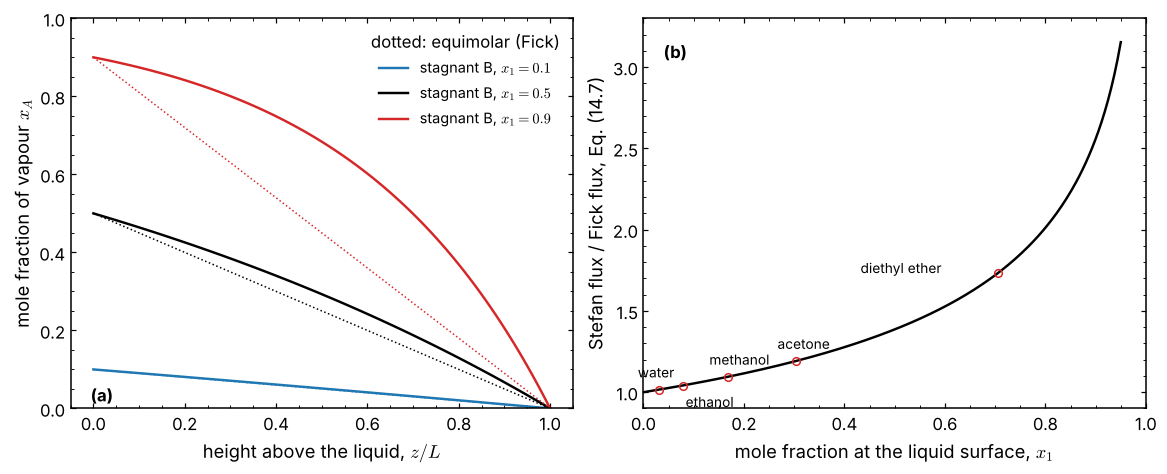

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
zeta = np.linspace(0, 1, 101)
for x1, style in ((0.1, "C0"), (0.5, "k"), (0.9, "C3")):
    ax1.plot(zeta, diffusion.film_profile(zeta, x1, 0.0), style + "-", label=fr"stagnant B, $x_1 = {x1}$")
    ax1.plot(zeta, diffusion.film_profile(zeta, x1, 0.0, sigma=0.0), style + ":", lw=1.0)
ax1.set_xlabel(r"height above the liquid, $z/L$")
ax1.set_ylabel(r"mole fraction of vapour $x_A$")
ax1.set_ylim(0, 1)
ax1.legend(loc="upper right", title="dotted: equimolar (Fick)")
panel_label(ax1, "(a)", x=0.04, y=0.06)

xg = np.linspace(1e-4, 0.95, 300)
ax2.plot(xg, -np.log(1 - xg) / xg, "k-")
for label, x in x_25.items():
    ax2.plot(x, -math.log(1 - x) / x, "C3o", ms=5, mfc="none")
    offset = {"water": (-14, 8), "ethanol": (2, -14), "methanol": (-12, 8), "acetone": (-12, 8),
              "diethyl ether": (-90, 0)}[label]
    ax2.annotate(label, (x, -math.log(1 - x) / x), textcoords="offset points", xytext=offset, fontsize=9)
ax2.set_xlabel(r"mole fraction at the liquid surface, $x_1$")
ax2.set_ylabel(r"Stefan flux / Fick flux, Eq. (14.7)")
ax2.set_xlim(0, 1)
ax2.set_ylim(0.9, 3.3)
panel_label(ax2, "(b)", x=0.04, y=0.94)
plt.show()

**Figure 14.1.** (a) Vapour profiles across a stagnant gas film, Eq. (14.5), for three
surface mole fractions, with the linear profiles of equimolar counter-diffusion (dotted).
(b) The enhancement of evaporation by drift, Eq. (14.7), with the saturated vapours of
five liquids at 25 °C.

The stagnant-gas profiles bulge upwards: the vapour concentration stays high over most of
the layer and drops steeply near the top. Near the liquid, where B must diffuse fastest
against the drift, the gradient of $x_A$ is smallest. For water at room temperature the
drift adds only 1.6 %, and Fick's law is good enough; for acetone it adds 19 % and for
diethyl ether 73 %.

## 14.4 The Stefan tube

A narrow vertical tube is partly filled with a liquid and kept at constant temperature,
and a gentle stream of air sweeps its mouth. The vapour diffuses up through
the still air in the tube, and the liquid level falls slowly. If the level falls slowly
compared with the time $s^2/D$ that diffusion needs to set up the profile, the flux at
any moment is that of a stagnant film of the current depth $s$, Eq. (14.5). The liquid,
of molar density $c_L = \rho_L/M$, recedes as $c_L\,ds/dt = N_A$, and integrating gives

$$
s^2 - s_0^2 = \frac{2D_{AB}}{r}\ln\frac{1 - x_{top}}{1 - x_s}\;t , \qquad r = \frac{c_L}{c} ,
\tag{14.8}
$$

with $x_s = p_{sat}/p$ at the liquid surface and $x_{top}$ at the mouth, zero for a clean air
stream (`diffusion.stefan_tube_level`). The square of the depth grows linearly in time: the
deeper the level, the longer the diffusion path and the slower it falls. Measuring the
level against time gives $D_{AB}$, and this is one of the oldest ways of measuring vapour
diffusivities.

For ethanol at 25 °C the vapour pressure is 7.89 kPa ($x_s = 0.078$) and the liquid
density 785 kg/m³, both from the reference equation of state of Schroeder, Penoncello and
Schroeder (2014).

In [5]:
c25 = P_ATM / (R_GAS * T25)
eth = properties.solvent_saturation("ethanol", T25)
x_s = eth["p_sat"] / P_ATM
r_eth = eth["rho_l"] / eth["M"] / c25
D_eth = properties.fuller_diffusivity("C2H5OH", "Air", T25)
K_eth = 2 * D_eth / r_eth * math.log(1 / (1 - x_s))
print(f"ethanol at 25 C: x_s = {x_s:.4f}, r = c_L/c = {r_eth:.0f}, D = {D_eth * 1e6:.2f} mm2/s (Eq. 14.3)")
for s1 in (0.020, 0.030, 0.050):
    print(f"  level from 10 to {1e3 * s1:.0f} mm below the mouth: {(s1**2 - 0.01**2) / K_eth / 3600:6.1f} h")
for dT in (0.1, 1.0):
    x2 = properties.solvent_saturation("ethanol", T25 + dT)["p_sat"] / P_ATM
    err = math.log(1 - x_s) / math.log(1 - x2) - 1
    print(f"  bath {dT} K warmer than assumed: D inferred from Eq. (14.8) {100 * -err:.1f} % too high")

ethanol at 25 C: x_s = 0.0778, r = c_L/c = 417, D = 12.28 mm2/s (Eq. 14.3)
  level from 10 to 20 mm below the mouth:   17.5 h
  level from 10 to 30 mm below the mouth:   46.6 h
  level from 10 to 50 mm below the mouth:  139.7 h
  bath 0.1 K warmer than assumed: D inferred from Eq. (14.8) 0.6 % too high
  bath 1.0 K warmer than assumed: D inferred from Eq. (14.8) 5.8 % too high


The level falls 10 mm in the first 17.5 hours, and from 10 to 50 mm in 140 hours, almost six
days. The experiment is slow but needs only a ruler and a thermostat. Its weakness is the
temperature: the vapour pressure of ethanol rises about 6 % per kelvin, and Eq. (14.8) turns
an unnoticed 1 K into a diffusivity 5.8 % too high. A good Stefan tube is held to 0.1 K, and
even then the liquid surface runs slightly colder than the bath, because evaporation takes
latent heat from it (Chapter 17).

## 14.5 A field after rain

After rain, a soil surface first evaporates almost as fast as open water, fed by capillary
flow from below. Within a day or two the top dries out, capillary contact breaks, and a dry
layer forms. From then on water evaporates at the bottom of the dry layer and its vapour
must diffuse to the surface through the air-filled pores; the dry layer thickens, the
diffusion path grows, and the loss slows down. This is a Stefan tube with two changes.
The gas fills only a fraction of the volume and winds round the grains, which lowers the
effective diffusivity; Millington and Quirk (1961) proposed

$$
\frac{D_{eff}}{D} = \frac{\theta_a^{10/3}}{\phi^2} = \phi^{4/3} \ \text{in a dry layer} ,
\tag{14.9}
$$

with $\phi$ the porosity and $\theta_a$ the air-filled porosity, equal to $\phi$ when the
layer is dry. And the "liquid" is water held at a volume fraction $\theta_w$, so that
$c_L = \rho_w\theta_w/M_w$. The front then follows Eq. (14.8) with $D_{eff}$ in place of
$D$, and the water lost per unit area, in millimetres, is

$$
E = \theta_w\left(s - s_0\right) .
\tag{14.10}
$$

The pores at the front are saturated, $x_s = p_{sat}/p$, and at the surface the vapour is in
equilibrium with the air, $x_{top} = \mathrm{RH}\,p_{sat}/p$. Take a loam with
$\phi = 0.45$ holding $\theta_w = 0.20$ below the front, everything at 25 °C, and the dry
layer starting from the surface ($s_0 = 0$).

In [6]:
phi, theta_w = 0.45, 0.20
p_w = properties.saturated_water(T25)["p_sat"]
D_w = properties.water_vapour_diffusivity_air(T25)
D_eff = D_w * diffusion.millington_quirk(phi)
r_soil = 1000.0 * theta_w / 0.018015 / c25
print(f"water vapour: D = {D_w * 1e6:.2f} mm2/s, D_eff = {D_eff * 1e6:.2f} mm2/s (factor {diffusion.millington_quirk(phi):.3f}); r = {r_soil:.0f}")


def dry_front(t, RH, phi=phi, theta_w=theta_w, s0=0.0):
    D_e = D_w * diffusion.millington_quirk(phi)
    r = 1000.0 * theta_w / 0.018015 / c25
    return diffusion.stefan_tube_level(t, s0, D_e, p_w / P_ATM, RH * p_w / P_ATM, r)


for RH in (0.3, 0.5, 0.8):
    s = [dry_front(d * 86400.0, RH) for d in (1, 10, 30)]
    print(f"air at {100 * RH:.0f} % RH: dry layer {1e3 * s[0]:4.1f} / {1e3 * s[1]:4.1f} / {1e3 * s[2]:4.1f} mm after 1 / 10 / 30 days;"
          f" water lost {1e3 * theta_w * s[0]:4.1f} / {1e3 * theta_w * s[1]:4.1f} / {1e3 * theta_w * s[2]:4.1f} mm")
last10 = theta_w * (dry_front(30 * 86400.0, 0.3) - dry_front(20 * 86400.0, 0.3))
print(f"at 30 % RH the first day loses {1e3 * theta_w * dry_front(86400.0, 0.3):.2f} mm, days 21-30 together {1e3 * last10:.2f} mm")

water vapour: D = 25.52 mm2/s, D_eff = 8.80 mm2/s (factor 0.345); r = 272
air at 30 % RH: dry layer 11.2 / 35.4 / 61.3 mm after 1 / 10 / 30 days; water lost  2.2 /  7.1 / 12.3 mm
air at 50 % RH: dry layer  9.5 / 29.9 / 51.9 mm after 1 / 10 / 30 days; water lost  1.9 /  6.0 / 10.4 mm
air at 80 % RH: dry layer  6.0 / 19.0 / 32.9 mm after 1 / 10 / 30 days; water lost  1.2 /  3.8 /  6.6 mm
at 30 % RH the first day loses 2.24 mm, days 21-30 together 2.25 mm


In dry summer air at 30 % relative humidity the dry layer is 11 mm deep after one day,
35 mm after ten and 61 mm after a month, and the field has lost 12.3 mm of water. The loss
grows as $\sqrt{t}$: the first day costs as much as the last ten days together. Humid air
slows the loss, but less than one might expect: at 80 % humidity the month still costs
6.6 mm, because the driving force is the difference $x_s - x_{top}$, and even humid air is
well below saturation compared with the wet soil. Most of the loss happens early; Exercise 3
asks whether loosening the top few centimetres after rain, an old practice of dry farming,
can reduce it.

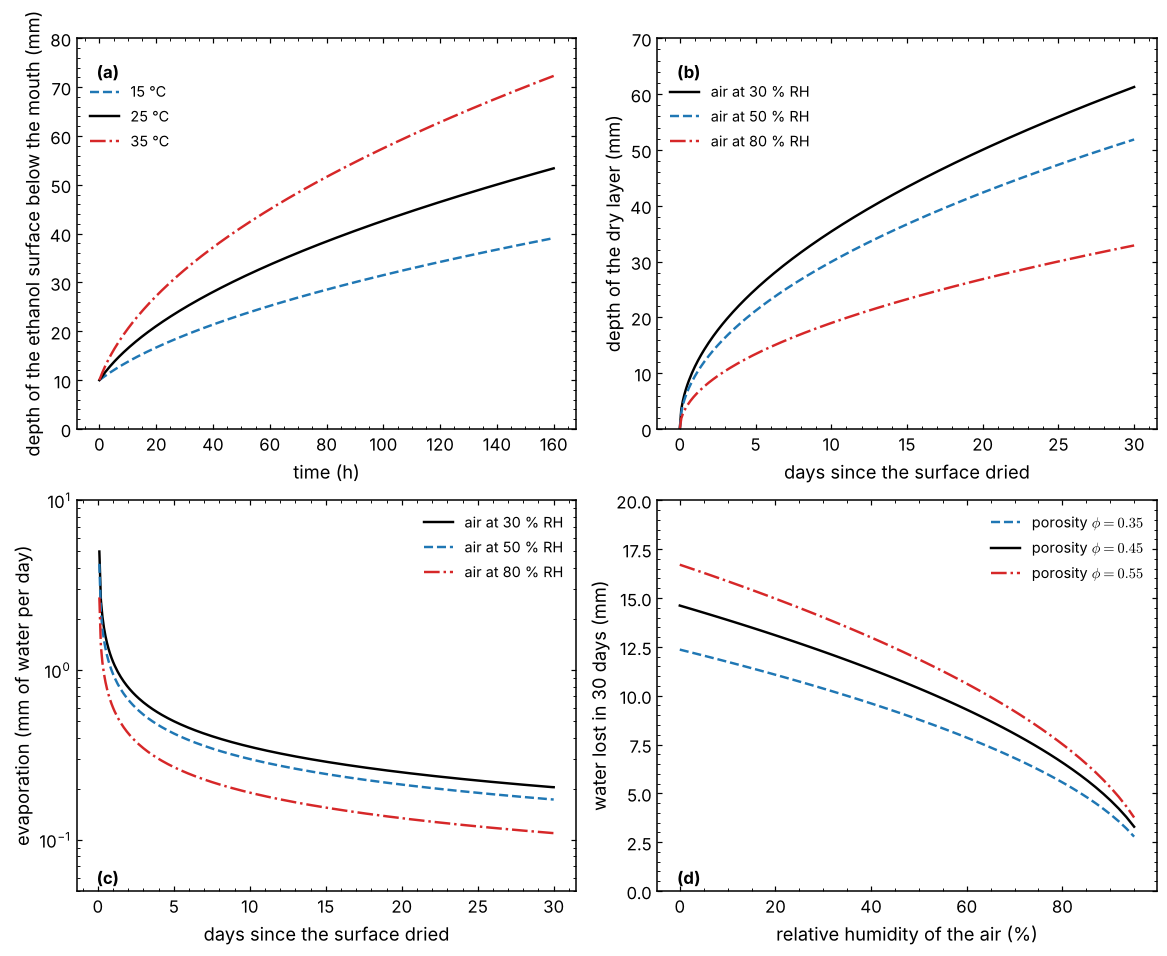

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

t_h = np.linspace(0, 160, 300)
for T_c, style in ((15, "C0--"), (25, "k-"), (35, "C3-.")):
    T = T_c + 273.15
    c = P_ATM / (R_GAS * T)
    e = properties.solvent_saturation("ethanol", T)
    s = diffusion.stefan_tube_level(t_h * 3600, 0.010, properties.fuller_diffusivity("C2H5OH", "Air", T),
                                    e["p_sat"] / P_ATM, 0.0, e["rho_l"] / e["M"] / c)
    ax1.plot(t_h, 1e3 * s, style, label=f"{T_c} °C")
ax1.set_xlabel("time (h)")
ax1.set_ylabel("depth of the ethanol surface below the mouth (mm)")
ax1.set_ylim(0, 80)
ax1.legend(loc="upper left", bbox_to_anchor=(0.0, 0.92))
panel_label(ax1, "(a)", x=0.04, y=0.94)

days = np.linspace(0, 30, 300)
for RH, style in ((0.3, "k-"), (0.5, "C0--"), (0.8, "C3-.")):
    ax2.plot(days, 1e3 * dry_front(days * 86400.0, RH), style, label=f"air at {100 * RH:.0f} % RH")
    rate = theta_w * np.gradient(dry_front(days * 86400.0, RH), days)
    ax3.semilogy(days[1:], 1e3 * rate[1:], style, label=f"air at {100 * RH:.0f} % RH")
ax2.set_xlabel("days since the surface dried")
ax2.set_ylabel("depth of the dry layer (mm)")
ax2.set_ylim(0, 70)
ax2.legend(loc="upper left", bbox_to_anchor=(0.0, 0.92))
panel_label(ax2, "(b)", x=0.04, y=0.94)
ax3.set_xlabel("days since the surface dried")
ax3.set_ylabel("evaporation (mm of water per day)")
ax3.set_ylim(0.05, 10)
ax3.legend(loc="upper right")
panel_label(ax3, "(c)", x=0.04, y=0.06)

RH_g = np.linspace(0.0, 0.95, 60)
for ph, style in ((0.35, "C0--"), (0.45, "k-"), (0.55, "C3-.")):
    ax4.plot(100 * RH_g, [1e3 * theta_w * dry_front(30 * 86400.0, RH, phi=ph) for RH in RH_g], style,
             label=fr"porosity $\phi = {ph}$")
ax4.set_xlabel("relative humidity of the air (%)")
ax4.set_ylabel("water lost in 30 days (mm)")
ax4.set_ylim(0, 20)
ax4.legend(loc="upper right")
panel_label(ax4, "(d)", x=0.04, y=0.06)
plt.show()

**Figure 14.2.** (a) The level of ethanol in a Stefan tube at three temperatures, starting
10 mm below the mouth, Eq. (14.8). (b) Depth of the dry layer in a loam after the surface
dries, and (c) the daily evaporation, for air at three humidities. (d) Water lost in the
first 30 days against air humidity, for three porosities, Eqs. (14.8)–(14.10).

Warming the ethanol by 10 K roughly doubles the rate of fall in (a), almost all of it
through the vapour pressure; the diffusivity rises only 6 %. In (c), the daily loss falls
from several millimetres in the first hours to 0.1–0.2 mm after a month. A coarser,
more porous soil in (d) dries faster: Eq. (14.9) makes the dry layer conduct vapour as
$\phi^{4/3}$, and a given loss empties fewer pores.

## 14.6 Checks

Equation (14.8) rests on two assumptions: that the gas column is in steady state at every
moment, and that the gas phase contains no vapour worth counting compared with the liquid.
Both can be dropped. With the depth $z$ measured down from the mouth, the gas phase obeys

$$
\frac{\partial x}{\partial t} + v^*\frac{\partial x}{\partial z} = D\frac{\partial^2 x}{\partial z^2} ,
\qquad 0 < z < s(t) ,
\tag{14.11}
$$

where the molar-average velocity $v^*$ is uniform in $z$ because $c$ is constant. Balances of
A and B across the moving liquid surface give $v^* = -(r - 1)\,ds/dt$ and
$D\,\partial x/\partial z = r(1 - x_s)\,ds/dt$ at $z = s$, with $x = x_{top}$ at the mouth.

**An exact solution.** If the liquid starts at the mouth, the problem has no length scale,
and with $\eta = z/2\sqrt{Dt}$ it becomes an ordinary differential equation,
$x'' + 2[\eta + (r-1)\beta]x' = 0$, with the level at $s = 2\beta\sqrt{Dt}$. Its solution is

$$
x = x_{top} + C\left[\operatorname{erf}(\eta + a) - \operatorname{erf}a\right], \quad a = (r - 1)\beta ,
\qquad
x_s - x_{top} = \sqrt{\pi}\,r\beta(1 - x_s)\,e^{r^2\beta^2}\left[\operatorname{erfc}a - \operatorname{erfc}(r\beta)\right] ,
\tag{14.12}
$$

and the last equation fixes $\beta$ (`reference.stefan_tube_exact`). The quasi-steady
formula (14.8) gives $\beta^2 = \ln[(1 - x_{top})/(1 - x_s)]/2r$ instead.

**A numerical solution.** Equation (14.11) is solved on a grid that moves with the level,
$\xi = z/s(t)$, by central differences and a stiff integrator, with the level advanced by
the interface condition (`reference.stefan_tube_march`). It is started either from the
exact profile at a small time, to test its convergence, or from a tube full of clean air
above the liquid, to see how long the start-up lasts.

**Fuller against measurements.** Equation (14.3) is compared with the diffusivities of water
vapour, carbon dioxide and methane in air recommended by Massman (1998) from his review of
the measurements, $D = D_0 (T/273.15\ \mathrm{K})^{1.81}$.

In [8]:
x_list, r_list = (0.078, 0.3, 0.7, 0.95), np.array([3.0, 10.0, 30.0, 100.0, 300.0, 1000.0, 1e4])
qs_err = {}
for xs in x_list:
    qs_err[xs] = np.array([reference.stefan_tube_exact(xs, 0.0, r)[0] / math.sqrt(math.log(1 / (1 - xs)) / (2 * r)) - 1
                           for r in r_list])
print("quasi-steady beta relative to exact, r = 10, 1000:", "; ".join(f"x_s {xs}: {qs_err[xs][1]:.1e}, {qs_err[xs][5]:.1e}" for xs in x_list))
b_eth, prof_eth = reference.stefan_tube_exact(x_s, 0.0, r_eth)
print(f"ethanol at 25 C: exact beta {b_eth:.8f}, quasi-steady {math.sqrt(math.log(1 / (1 - x_s)) / (2 * r_eth)):.8f}")
b_soil, _ = reference.stefan_tube_exact(p_w / P_ATM, 0.3 * p_w / P_ATM, r_soil)
print(f"soil at 30 % RH: exact / quasi-steady beta - 1 = {b_soil / math.sqrt(math.log((1 - 0.3 * p_w / P_ATM) / (1 - p_w / P_ATM)) / (2 * r_soil)) - 1:.1e}")

# march from the exact profile at t0 = 10 s to 10 h, ethanol
t0, t1 = 10.0, 36000.0
n_grid = np.array([12, 25, 50, 100, 200])
march_err = []
for n in n_grid:
    xi = np.linspace(0, 1, n + 1)
    sol = reference.stefan_tube_march(x_s, 0.0, r_eth, D_eth, 2 * b_eth * math.sqrt(D_eth * t0), (t0, t1), n=n,
                                      x0=prof_eth(xi * b_eth))
    march_err.append(abs(sol.y[-1, -1] / (2 * b_eth * math.sqrt(D_eth * t1)) - 1))
march_err = np.array(march_err)
print("march started from the exact profile, error of s after 10 h:", " ".join(f"{e:.1e}" for e in march_err))

# start-up: a tube full of air above ethanol 10 mm down
s0 = 0.010
tau = s0**2 / D_eth
t_su = np.geomspace(0.05 * tau, 500 * tau, 40)
su = reference.stefan_tube_march(x_s, 0.0, r_eth, D_eth, s0, (0.0, t_su[-1]), n=200, t_eval=t_su)
dev_su = (su.y[-1] ** 2 - s0**2) / (K_eth * su.t) - 1
offset = np.mean((su.y[-1, -10:] ** 2 - s0**2 - K_eth * su.t[-10:]) / (2 * s0))
print(f"start-up from clean air: tau = s0^2/D = {tau:.1f} s; (s^2 - s0^2)/(K t) - 1 = {dev_su[np.searchsorted(su.t, tau)]:.2f} at tau,"
      f" {dev_su[-1]:.1e} at 500 tau; level offset {offset * 1e6:.2f} um")
print(f"vapour needed to fill the column, as liquid depth: {c25 * s0 * (x_s / 2) / (eth['rho_l'] / eth['M']) * 1e6:.2f} um (linear profile)")

massman = {"H2O": 2.178e-5, "CO2": 1.381e-5, "CH4": 1.952e-5}
T_m = np.linspace(233.15, 333.15, 41)
ratio_m = {g: np.array([properties.fuller_diffusivity(g, "Air", T) / (D0 * (T / 273.15) ** 1.81) for T in T_m])
           for g, D0 in massman.items()}
for g in massman:
    print(f"Fuller / Massman for {g}: {ratio_m[g].min():.3f} to {ratio_m[g].max():.3f} between -40 and 60 C")

quasi-steady beta relative to exact, r = 10, 1000: x_s 0.078: 6.6e-04, 6.6e-06; x_s 0.3: 2.7e-03, 2.7e-05; x_s 0.7: 7.7e-03, 7.6e-05; x_s 0.95: 1.4e-02, 1.4e-04
ethanol at 25 C: exact beta 0.00985795, quasi-steady 0.00985779
soil at 30 % RH: exact / quasi-steady beta - 1 = 6.8e-06


march started from the exact profile, error of s after 10 h: 7.2e-06 1.7e-06 4.2e-07 1.1e-07 3.8e-08


start-up from clean air: tau = s0^2/D = 8.1 s; (s^2 - s0^2)/(K t) - 1 = 0.30 at tau, 6.8e-04 at 500 tau; level offset 0.65 um
vapour needed to fill the column, as liquid depth: 0.93 um (linear profile)
Fuller / Massman for H2O: 0.977 to 0.998 between -40 and 60 C
Fuller / Massman for CO2: 0.968 to 0.989 between -40 and 60 C
Fuller / Massman for CH4: 0.912 to 0.932 between -40 and 60 C


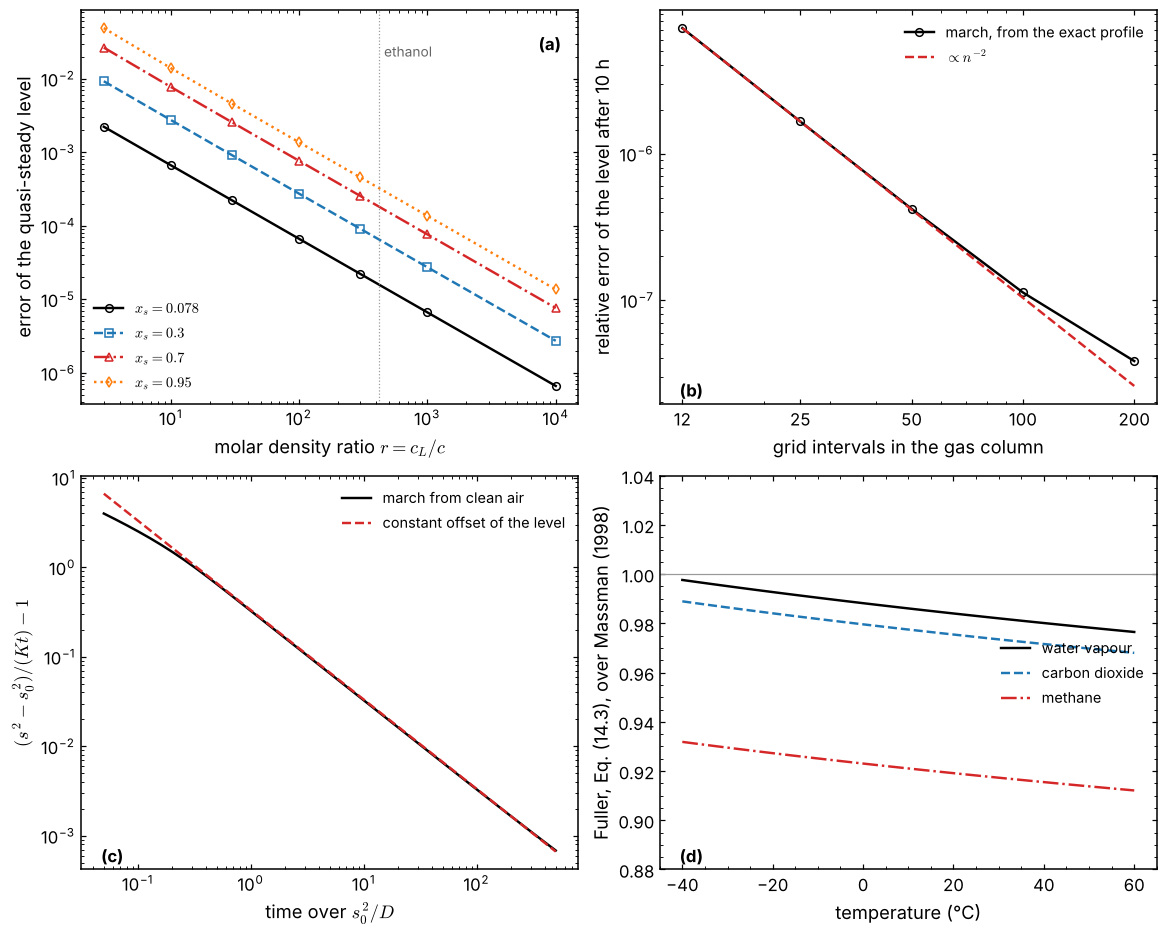

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

for xs, style in zip(x_list, ("ko-", "C0s--", "C3^-.", "C1d:")):
    ax1.loglog(r_list, np.abs(qs_err[xs]), style, ms=5, mfc="none", label=fr"$x_s = {xs}$")
ax1.axvline(r_eth, color="0.6", ls=":", lw=0.8)
ax1.text(r_eth * 1.1, 2e-2, "ethanol", color="0.4", fontsize=9)
ax1.set_xlabel(r"molar density ratio $r = c_L/c$")
ax1.set_ylabel("error of the quasi-steady level")
ax1.legend(loc="lower left")
panel_label(ax1, "(a)", x=0.92, y=0.94)

ax2.loglog(n_grid, march_err, "ko-", ms=5, mfc="none", label="march, from the exact profile")
ax2.loglog(n_grid, march_err[1] * (n_grid[1] / n_grid) ** 2, "C3--", label=r"$\propto n^{-2}$")
ax2.set_xticks(n_grid)
ax2.xaxis.set_major_formatter(plt.ScalarFormatter())
ax2.xaxis.set_minor_formatter(plt.NullFormatter())
ax2.set_xlabel("grid intervals in the gas column")
ax2.set_ylabel("relative error of the level after 10 h")
ax2.legend(loc="upper right")
panel_label(ax2, "(b)", x=0.04, y=0.06)

ax3.loglog(su.t / tau, dev_su, "k-", label="march from clean air")
ax3.loglog(su.t / tau, 2 * s0 * offset / (K_eth * su.t), "C3--", label="constant offset of the level")
ax3.set_xlabel(r"time over $s_0^2/D$")
ax3.set_ylabel(r"$(s^2 - s_0^2)/(Kt) - 1$")
ax3.legend(loc="upper right")
panel_label(ax3, "(c)", x=0.04, y=0.06)

for g, style, label in (("H2O", "k-", "water vapour"), ("CO2", "C0--", "carbon dioxide"), ("CH4", "C3-.", "methane")):
    ax4.plot(T_m - 273.15, ratio_m[g], style, label=label)
ax4.axhline(1, color="0.6", lw=0.8)
ax4.set_xlabel("temperature (°C)")
ax4.set_ylabel("Fuller, Eq. (14.3), over Massman (1998)")
ax4.set_ylim(0.88, 1.04)
ax4.legend(loc="center right")
panel_label(ax4, "(d)", x=0.04, y=0.06)
plt.show()

**Figure 14.3.** Checks. (a) Error of the quasi-steady formula (14.8) against the exact
solution (14.12), as a function of the molar density ratio of liquid to gas, for four
surface mole fractions. (b) Convergence of the moving-grid march to the exact solution.
(c) Start-up of a Stefan tube filled with clean air, against time scaled by $s_0^2/D$.
(d) The Fuller correlation against the diffusivities recommended by Massman (1998).

The quasi-steady formula errs by about $0.1\,x_s/r$, so for a liquid evaporating into a
gas at atmospheric pressure, where $r$ is several hundred, it is exact to $10^{-4}$ or
better: $2\times10^{-5}$ for ethanol and $7\times10^{-6}$ for the soil. It fails only when the evaporating phase
is not much denser than the gas, as for a liquid near its critical point or a nearly dry
porous medium. The march converges at second order to the exact solution, to
$4\times10^{-8}$. Started from clean air, it approaches Eq. (14.8) within one per cent after
about 30 times $s_0^2/D$, four minutes here; what remains is a fixed offset of the level by
0.65 μm, of the order of the liquid that evaporated to fill the column with vapour (0.9 μm
for a linear profile). In (d), the Fuller correlation agrees with the recommended values for
water vapour and carbon dioxide within 3 %, but is 7–9 % low for methane; its temperature
exponent of 1.75 is slightly lower than the 1.81 of the review.

## 14.7 What to trust

* *Fuller's correlation* is good to a few per cent for simple molecules and 5–10 % for
  others; where a measured value exists, it should be used. A Stefan tube measurement is
  only as good as its temperature control, about 6 % per kelvin for ethanol.
* *The mouth of the tube* is assumed to be at $x = 0$. A strong air stream stirs the top of
  the tube, a weak one leaves vapour there; both change the effective length by a fraction
  of the diameter, which matters for short columns.
* *Evaporative cooling.* The latent heat of the evaporating liquid cools its surface and
  lowers its vapour pressure; Chapter 17 treats heat and mass transfer together.
* *The soil model* takes a sharp front, a uniform temperature and still air. Real soils
  have a gradual drying zone, liquid films and vapour driven by daily temperature swings;
  the surface can be 30 K warmer than the air at noon. The model gives the order of
  magnitude and the $\sqrt{t}$ law, which field measurements of second-stage evaporation
  broadly follow, not a forecast for a particular field.
* *Multicomponent mixtures* need the Maxwell–Stefan equations; Fick's law with one
  diffusivity is exact only for two species.

## Summary

* Fick's law (14.1) gives the diffusive flux relative to the mixture; the total flux (14.2)
  adds the drift of the mixture, which matters when the diffusing species is not dilute.
* Gas diffusivities are 10–80 mm²/s at room temperature and grow as $T^{1.75}/p$, Eq. (14.3);
  liquid diffusivities are near $10^{-9}$ m²/s.
* Through a stagnant gas, the flux follows Stefan's law (14.5), larger than Fick's (14.6)
  by the factor (14.7): 1.6 % for water at 25 °C, 73 % for diethyl ether.
* In a Stefan tube the square of the depth grows linearly in time, Eq. (14.8); this
  measures diffusivities. An exact solution (14.12) shows the formula is exact to
  $10^{-4}$ when the liquid is much denser than the gas.
* After rain, a dry soil layer works as a Stefan tube, Eqs. (14.9)–(14.10): in a month of
  dry air a loam loses about 12 mm of water, half of it in the first week.

## Exercises

Sample solutions are in [`solutions/part4_mass_transfer/14_solutions.ipynb`](../../solutions/part4_mass_transfer/14_solutions.ipynb).

1. **Methanol in a Stefan tube.** Repeat the ethanol calculation of Section 14.4 for
   methanol at 25 °C. How long does the level take to fall from 10 to 20 mm? The
   thermostat drifts by 0.5 K during a run: what error does this cause in the measured
   diffusivity?
2. **A catalytic surface.** A gas A diffuses through a film 1 mm thick to a catalyst
   surface, where it cracks instantly as A → 2B, so that $x_A = 0$ at the surface and
   $N_B = -2N_A$. With $x_A = 0.5$ outside the film, $c = 40$ mol/m³ and
   $D = 2\times10^{-5}$ m²/s, find the flux of A from Eq. (14.4) with $\sigma = -1$, and
   compare it with Fick's law and with Stefan's law. Why is it smaller than both?
3. **A dust mulch.** Immediately after rain, a farmer loosens the top 50 mm of the loam of
   Section 14.5, which then dries within a day and has a porosity of 0.55. Below it the
   soil is unchanged. How much water does the field lose in the following 30 days in air
   at 30 % humidity, counting the water of the loosened layer, compared with untilled soil
   that dries from the surface down? (The vapour crosses the loose layer and the growing dry
   layer below it in series; integrate the quasi-steady front numerically.) What does the
   answer say about where a dust mulch can save water?
4. **Vapour in the wall of Chapter 2.** The wall of Section 2.1 (plaster, brick, mineral
   wool, render) separates a room at 20 °C and 50 % humidity from air at −35 °C and 85 %
   humidity. Water vapour diffuses through it, each layer resisting like a still air layer
   $\mu$ times as thick as itself, with assumed typical values $\mu$ = 10 for plaster and
   brick, 1 for mineral wool and 25 for the render. Compare the vapour pressure through the
   wall with the saturation pressure (over ice below 0 °C) at the temperatures of
   Chapter 2. Where does vapour condense, how much per day, and what does a vapour barrier
   with $\mu d = 20$ m on the warm side of the wool change?

## Suggested references

* A. Fick, "Ueber Diffusion", *Ann. Phys.* **170**, 59 (1855).
* J. Stefan, "Über das Gleichgewicht und die Bewegung, insbesondere die Diffusion von
  Gasgemengen", *Sitzungsber. Akad. Wiss. Wien* **63**, 63 (1871).
* E. N. Fuller, P. D. Schettler and J. C. Giddings, "A new method for prediction of binary
  gas-phase diffusion coefficients", *Ind. Eng. Chem.* **58**(5), 18 (1966).
* E. N. Fuller, K. Ensley and J. C. Giddings, "Diffusion of halogenated hydrocarbons in
  helium. The effect of structure on collision cross sections", *J. Phys. Chem.* **73**,
  3679 (1969).
* W. J. Massman, "A review of the molecular diffusivities of H₂O, CO₂, CH₄, CO, O₃, SO₂,
  NH₃, N₂O, NO, and NO₂ in air, O₂ and N₂ near STP", *Atmos. Environ.* **32**, 1111 (1998).
* R. J. Millington and J. P. Quirk, "Permeability of porous solids", *Trans. Faraday Soc.*
  **57**, 1200 (1961).
* J. A. Schroeder, S. G. Penoncello and J. S. Schroeder, "A fundamental equation of state
  for ethanol", *J. Phys. Chem. Ref. Data* **43**, 043102 (2014).
* E. L. Cussler, *Diffusion: Mass Transfer in Fluid Systems*, 3rd ed. (Cambridge
  University Press, 2009).

---

**Previous:** [13. View factors and enclosures](../part3_radiation/13_view_factors_enclosures.ipynb) &nbsp;·&nbsp; **Next:** [15. Diffusion with reaction](15_diffusion_reaction.ipynb)